In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os
os.chdir('/content/drive/MyDrive/DataACQ/DAQProject')
!pwd

/content/drive/MyDrive/DataACQ/DAQProject


In [ ]:
import pandas as pd

df = pd.read_csv('UsedCarData.csv')
df.head() #Head used to visualise the type of data in the dataset

,Unnamed: 0,brand,model,color,registration_date,year,price_in_euro,power_kw,power_ps,transmission_type,fuel_type,fuel_consumption_l_100km,fuel_consumption_g_km,mileage_in_km,offer_description
0,0,alfa-romeo,Alfa Romeo GTV,red,10/1995,1995,1300,148,201,Manual,Petrol,"10,9 l/100 km",260 g/km,160500.0,2.0 V6 TB
1,1,alfa-romeo,Alfa Romeo 164,black,02/1995,1995,24900,191,260,Manual,Petrol,NaN,- (g/km),190000.0,"Q4 Allrad, 3.2L GTA"
2,2,alfa-romeo,Alfa Romeo Spider,black,02/1995,1995,5900,110,150,Unknown,Petrol,NaN,- (g/km),129000.0,ALFA ROME 916
3,3,alfa-romeo,Alfa Romeo Spider,black,07/1995,1995,4900,110,150,Manual,Petrol,"9,5 l/100 km",225 g/km,189500.0,2.0 16V Twin Spark L
4,4,alfa-romeo,Alfa Romeo 164,red,11/1996,1996,17950,132,179,Manual,Petrol,"7,2 l/100 km",- (g/km),96127.0,"3.0i Super V6, absoluter Topzustand !"


In [ ]:
df = df.drop(columns=["offer_description"])

# Uneccesary column so I removed to tidy data

KeyError: "['offer_description'] not found in axis"

In [ ]:
df["mileage_in_km"] = df["mileage_in_km"].astype("Int64")

# to remove the decimal points from mileage as mileage doesnt contain decimals

In [ ]:
df["mileage_in_km"].head()

#doublechecking it worked

,mileage_in_km
0,160500
1,190000
2,129000
3,189500
4,96127


In [ ]:
df["fuel_consumption_g_km"] = (
    df["fuel_consumption_g_km"]
    .str.extract(r"(\d+\.?\d*)", expand=False)
    .astype(float)
)

In [ ]:
df.head()

,Unnamed: 0,brand,model,color,registration_date,year,price_in_euro,power_kw,power_ps,transmission_type,fuel_type,fuel_consumption_l_100km,fuel_consumption_g_km,mileage_in_km
0,0,alfa-romeo,Alfa Romeo GTV,red,10/1995,1995,1300,148,201,Manual,Petrol,"10,9 l/100 km",260.0,160500
1,1,alfa-romeo,Alfa Romeo 164,black,02/1995,1995,24900,191,260,Manual,Petrol,NaN,NaN,190000
2,2,alfa-romeo,Alfa Romeo Spider,black,02/1995,1995,5900,110,150,Unknown,Petrol,NaN,NaN,129000
3,3,alfa-romeo,Alfa Romeo Spider,black,07/1995,1995,4900,110,150,Manual,Petrol,"9,5 l/100 km",225.0,189500
4,4,alfa-romeo,Alfa Romeo 164,red,11/1996,1996,17950,132,179,Manual,Petrol,"7,2 l/100 km",NaN,96127


In [ ]:
df["fuel_consumption_l_100km"] = (
    df["fuel_consumption_l_100km"]
    .str.extract(r"(\d+\.?\d*)", expand=False)
    .astype(float)
)

In [ ]:
df.head()

,Unnamed: 0,brand,model,color,registration_date,year,price_in_euro,power_kw,power_ps,transmission_type,fuel_type,fuel_consumption_l_100km,fuel_consumption_g_km,mileage_in_km
0,0,alfa-romeo,Alfa Romeo GTV,red,10/1995,1995,1300,148,201,Manual,Petrol,10.0,260.0,160500
1,1,alfa-romeo,Alfa Romeo 164,black,02/1995,1995,24900,191,260,Manual,Petrol,NaN,NaN,190000
2,2,alfa-romeo,Alfa Romeo Spider,black,02/1995,1995,5900,110,150,Unknown,Petrol,NaN,NaN,129000
3,3,alfa-romeo,Alfa Romeo Spider,black,07/1995,1995,4900,110,150,Manual,Petrol,9.0,225.0,189500
4,4,alfa-romeo,Alfa Romeo 164,red,11/1996,1996,17950,132,179,Manual,Petrol,7.0,NaN,96127


In [ ]:
df = df.drop(columns= "registration_date")

In [ ]:
df.head()

,Unnamed: 0,brand,model,color,year,price_in_euro,power_kw,power_ps,transmission_type,fuel_type,fuel_consumption_l_100km,fuel_consumption_g_km,mileage_in_km
0,0,alfa-romeo,Alfa Romeo GTV,red,1995,1300,148,201,Manual,Petrol,10.0,260.0,160500
1,1,alfa-romeo,Alfa Romeo 164,black,1995,24900,191,260,Manual,Petrol,NaN,NaN,190000
2,2,alfa-romeo,Alfa Romeo Spider,black,1995,5900,110,150,Unknown,Petrol,NaN,NaN,129000
3,3,alfa-romeo,Alfa Romeo Spider,black,1995,4900,110,150,Manual,Petrol,9.0,225.0,189500
4,4,alfa-romeo,Alfa Romeo 164,red,1996,17950,132,179,Manual,Petrol,7.0,NaN,96127


In [ ]:
df.shape

(251079, 13)

In [ ]:
df = df.replace(r"^\s*$", pd.NA, regex=True)

#to convert empty strings into proper empty rows for isnull()

In [ ]:
missing = df.isnull().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(df) * 100).round(2)
missing.sort_values("missing_count", ascending=False)

#To return data as % of missing data from column

,missing_count,missing_pct
fuel_consumption_g_km,36770,14.64
fuel_consumption_l_100km,26922,10.72
color,166,0.07
mileage_in_km,152,0.06
power_kw,134,0.05
power_ps,129,0.05
model,0,0.00
brand,0,0.00
Unnamed: 0,0,0.00
year,0,0.00


In [ ]:
df["year"] = pd.to_numeric(df["year"], errors="coerce")

#to convert the year column from string to integer for cleaning

In [ ]:
df = df[df["year"] <= 2023]

#to get rid of any data that the car is newer than 2023 to match the webscraping data

In [ ]:
df["year"].max()

#double checking the highest year car

2023.0

In [ ]:
df.head()

,Unnamed: 0,brand,model,color,year,price_in_euro,power_kw,power_ps,transmission_type,fuel_type,fuel_consumption_l_100km,fuel_consumption_g_km,mileage_in_km
0,0,alfa-romeo,Alfa Romeo GTV,red,1995.0,1300,148,201,Manual,Petrol,10.0,260.0,160500
1,1,alfa-romeo,Alfa Romeo 164,black,1995.0,24900,191,260,Manual,Petrol,NaN,NaN,190000
2,2,alfa-romeo,Alfa Romeo Spider,black,1995.0,5900,110,150,Unknown,Petrol,NaN,NaN,129000
3,3,alfa-romeo,Alfa Romeo Spider,black,1995.0,4900,110,150,Manual,Petrol,9.0,225.0,189500
4,4,alfa-romeo,Alfa Romeo 164,red,1996.0,17950,132,179,Manual,Petrol,7.0,NaN,96127


In [ ]:
df["transmission_type"].unique()

#To Display all the types of transmission types

array(['Manual', 'Unknown', 'Automatic', 'Semi-automatic'], dtype=object)

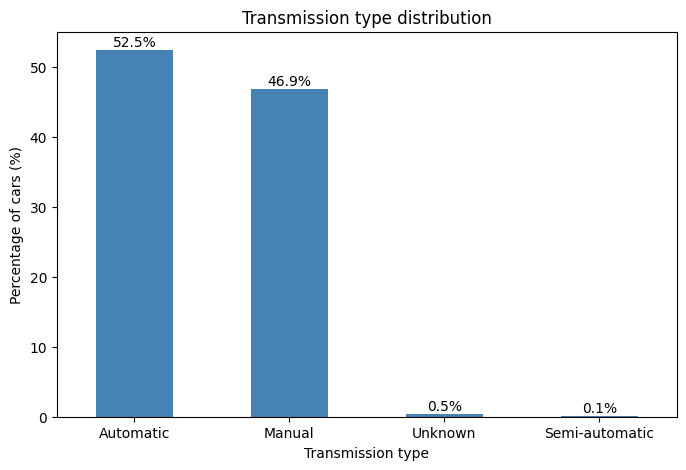

In [ ]:
import matplotlib.pyplot as plt

pct = df["transmission_type"].value_counts(normalize=True, dropna=False) * 100

ax = pct.plot(kind="bar", figsize=(8, 5), color="steelblue")
ax.set_ylabel("Percentage of cars (%)")
ax.set_xlabel("Transmission type")
ax.set_title("Transmission type distribution")
plt.xticks(rotation=0)

for i, v in enumerate(pct):
    ax.text(i, v + 0.5, f"{v:.1f}%", ha="center")

plt.show()

In [ ]:
df["transmission_type"].value_counts(dropna=False)

,count
transmission_type,
Automatic,131640
Manual,117780
Unknown,1143
Semi-automatic,317


As we can see from this data, we have 1,143 unknown transmissions & 317 semi automatic, to make this data as clean as possible, i will convert semi automatic to automatic, as they are classified as automatic on the ncap website

In [ ]:
df["transmission_type"] = df["transmission_type"].replace("Semi-automatic", "Automatic")

In [ ]:
df["transmission_type"].value_counts(dropna=False)

,count
transmission_type,
Automatic,131957
Manual,117780
Unknown,1143


In [ ]:
df.head(20)

,Unnamed: 0,brand,model,color,year,price_in_euro,power_kw,power_ps,transmission_type,fuel_type,fuel_consumption_l_100km,fuel_consumption_g_km,mileage_in_km
0,0,alfa-romeo,Alfa Romeo GTV,red,1995.0,1300,148,201,Manual,Petrol,10.0,260.0,160500
1,1,alfa-romeo,Alfa Romeo 164,black,1995.0,24900,191,260,Manual,Petrol,NaN,NaN,190000
2,2,alfa-romeo,Alfa Romeo Spider,black,1995.0,5900,110,150,Unknown,Petrol,NaN,NaN,129000
3,3,alfa-romeo,Alfa Romeo Spider,black,1995.0,4900,110,150,Manual,Petrol,9.0,225.0,189500
4,4,alfa-romeo,Alfa Romeo 164,red,1996.0,17950,132,179,Manual,Petrol,7.0,NaN,96127
5,5,alfa-romeo,Alfa Romeo Spider,red,1996.0,7900,110,150,Manual,Petrol,9.0,225.0,47307
6,6,alfa-romeo,Alfa Romeo 145,red,1996.0,3500,110,150,Manual,Petrol,8.0,210.0,230000
7,7,alfa-romeo,Alfa Romeo 164,black,1996.0,5500,132,179,Manual,Petrol,13.0,320.0,168000
8,8,alfa-romeo,Alfa Romeo Spider,black,1996.0,8990,141,192,Manual,Petrol,11.0,265.0,168600
9,9,alfa-romeo,Alfa Romeo Spider,black,1996.0,6976,110,150,Manual,Petrol,9.0,220.0,99000


In [ ]:
df.tail()

,Unnamed: 0,brand,model,color,year,price_in_euro,power_kw,power_ps,transmission_type,fuel_type,fuel_consumption_l_100km,fuel_consumption_g_km,mileage_in_km
251074,251074,volvo,Volvo XC40,white,2023.0,57990,192,261,Automatic,Hybrid,NaN,43.0,1229
251075,251075,volvo,Volvo XC90,white,2023.0,89690,173,235,Automatic,Diesel,7.0,202.0,4900
251076,251076,volvo,Volvo V60,white,2023.0,61521,145,197,Automatic,Diesel,4.0,125.0,1531
251077,251077,volvo,Volvo XC40,white,2023.0,57890,132,179,Automatic,Hybrid,NaN,45.0,1500
251078,251078,volvo,Volvo XC40,gold,2023.0,52900,160,218,Automatic,Electric,NaN,438.0,50


In [ ]:
df["fuel_type"].value_counts(dropna=False)

,count
fuel_type,
Petrol,143280
Diesel,86421
Hybrid,12607
Electric,5967
LPG,1255
CNG,508
Diesel Hybrid,476
Other,178
Unknown,96


Im going to combine hybrid & diesel hybrid as this will affect my results and they contain the same data

In [ ]:
df["fuel_type"] = df["fuel_type"].replace("Diesel Hybrid", "Hybrid")

In [ ]:
df["fuel_type"].value_counts(dropna=False)

,count
fuel_type,
Petrol,143280
Diesel,86421
Hybrid,13083
Electric,5967
LPG,1255
CNG,508
Other,178
Unknown,96
Hydrogen,82


In [ ]:
df.head()

,Unnamed: 0,brand,model,color,year,price_in_euro,power_kw,power_ps,transmission_type,fuel_type,fuel_consumption_l_100km,fuel_consumption_g_km,mileage_in_km
0,0,alfa-romeo,Alfa Romeo GTV,red,1995.0,1300,148,201,Manual,Petrol,10.0,260.0,160500
1,1,alfa-romeo,Alfa Romeo 164,black,1995.0,24900,191,260,Manual,Petrol,NaN,NaN,190000
2,2,alfa-romeo,Alfa Romeo Spider,black,1995.0,5900,110,150,Unknown,Petrol,NaN,NaN,129000
3,3,alfa-romeo,Alfa Romeo Spider,black,1995.0,4900,110,150,Manual,Petrol,9.0,225.0,189500
4,4,alfa-romeo,Alfa Romeo 164,red,1996.0,17950,132,179,Manual,Petrol,7.0,NaN,96127


In [ ]:
df["year"] = df["year"].astype("Int64")

In [ ]:
df.head()

,Unnamed: 0,brand,model,color,year,price_in_euro,power_kw,power_ps,transmission_type,fuel_type,fuel_consumption_l_100km,fuel_consumption_g_km,mileage_in_km
0,0,alfa-romeo,Alfa Romeo GTV,red,1995,1300,148,201,Manual,Petrol,10.0,260.0,160500
1,1,alfa-romeo,Alfa Romeo 164,black,1995,24900,191,260,Manual,Petrol,NaN,NaN,190000
2,2,alfa-romeo,Alfa Romeo Spider,black,1995,5900,110,150,Unknown,Petrol,NaN,NaN,129000
3,3,alfa-romeo,Alfa Romeo Spider,black,1995,4900,110,150,Manual,Petrol,9.0,225.0,189500
4,4,alfa-romeo,Alfa Romeo 164,red,1996,17950,132,179,Manual,Petrol,7.0,NaN,96127


In [ ]:
df["color"].value_counts(dropna=False)

#checking for duplicate colors

,count
color,
black,58686
grey,46751
white,40587
silver,34332
blue,32070
red,21245
brown,4411
green,3498
orange,3365


In [ ]:
import re

def clean(s):
    s = str(s).lower().strip()
    s = re.sub(r"[^a-z0-9 ]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

In [ ]:
import re

def strip_make(row):
    make = clean(row["brand"])
    model = clean(row["model"])
    if model.startswith(make + " "):
        model = model[len(make) + 1:]
    return model

df["model_k"] = df.apply(strip_make, axis=1)

In [ ]:
df.head()

,Unnamed: 0,brand,model,color,registration_date,year,price_in_euro,power_kw,power_ps,transmission_type,fuel_type,fuel_consumption_l_100km,fuel_consumption_g_km,mileage_in_km,offer_description,model_k
0,0,alfa-romeo,Alfa Romeo GTV,red,10/1995,1995,1300,148,201,Manual,Petrol,"10,9 l/100 km",260 g/km,160500.0,2.0 V6 TB,gtv
1,1,alfa-romeo,Alfa Romeo 164,black,02/1995,1995,24900,191,260,Manual,Petrol,NaN,- (g/km),190000.0,"Q4 Allrad, 3.2L GTA",164
2,2,alfa-romeo,Alfa Romeo Spider,black,02/1995,1995,5900,110,150,Unknown,Petrol,NaN,- (g/km),129000.0,ALFA ROME 916,spider
3,3,alfa-romeo,Alfa Romeo Spider,black,07/1995,1995,4900,110,150,Manual,Petrol,"9,5 l/100 km",225 g/km,189500.0,2.0 16V Twin Spark L,spider
4,4,alfa-romeo,Alfa Romeo 164,red,11/1996,1996,17950,132,179,Manual,Petrol,"7,2 l/100 km",- (g/km),96127.0,"3.0i Super V6, absoluter Topzustand !",164


In [ ]:
df[["brand", "model", "model_k"]].head(10)

,brand,model,model_k
0,alfa-romeo,Alfa Romeo GTV,gtv
1,alfa-romeo,Alfa Romeo 164,164
2,alfa-romeo,Alfa Romeo Spider,spider
3,alfa-romeo,Alfa Romeo Spider,spider
4,alfa-romeo,Alfa Romeo 164,164
5,alfa-romeo,Alfa Romeo Spider,spider
6,alfa-romeo,Alfa Romeo 145,145
7,alfa-romeo,Alfa Romeo 164,164
8,alfa-romeo,Alfa Romeo Spider,spider
9,alfa-romeo,Alfa Romeo Spider,spider


In [ ]:
from google.colab import files

df.to_csv("UsedCarKaggleDataCleaned.csv", index=False)
files.download("UsedCarKaggleDataCleaned.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>